# Rapport final — Optimisation de tournées de livraison (CVRP)

**Projet CesiCDP — Réponse à l'appel à manifestation d'intérêt de l'ADEME**

Ce rapport rassemble la modélisation mathématique formelle, l'analyse de complexité théorique, la résolution exacte par PLNE et Branch and Bound, l'algorithme génétique et l'étude expérimentale comparative complète sur 23 instances de référence VRPLIB. Le périmètre implémenté est le **CVRP niveau B** : dépôt unique, flotte homogène, capacité identique, demandes clients strictement positives et coûts d'arcs euclidiens symétriques.

**Résumé méthodologique.** 
1. Nous posons d'abord le problème et sa **formulation mathématique rigoureuse en PLNE** (variables, fonction objectif, contraintes de visite, de flot, de capacité et d'élimination des sous-tours).
2. À partir de cette formulation, nous menons l'**analyse théorique de complexité** : preuve d'appartenance à la classe NP et preuve de NP-difficulté au sens fort par réduction polynomiale du problème du voyageur de commerce (TSP).
3. Le **GA est la méthode retenue pour les grandes instances**. Le PLNE sert de référence sur les petites instances, afin de certifier certains optima et d'évaluer la qualité du GA.

---

**Plan du rapport**
1. Contexte et périmètre industriel
2. Données et modélisation mathématique en PLNE
3. Analyse théorique de complexité (NP-complétude & Réduction)
4. Du PLNE de référence au choix du GA
5. Choix du jeu d'essai expérimental (23 instances de référence VRPLIB)
6. Résolution exacte : PLNE et Branch and Bound (résultats et limites expérimentales)
7. Métaheuristique retenue : Algorithme Génétique (Architecture, Schéma fonctionnel, Décodage Split)
8. Étude expérimentale comparative et analyse des performances
9. Conclusion, limites et Plan d'Amélioration Stratégique
10. Références bibliographiques


## 1. Contexte et périmètre industriel

Dans le cadre de l'appel à manifestation d'intérêt de l'ADEME, l'entreprise **CesiCDP** souhaite optimiser ses tournées de livraison de marchandises afin de minimiser les distances parcourues, réduire la consommation d'énergie fossile et abaisser l'empreinte carbone de ses opérations logistiques urbaines.

Une flotte de véhicules utilitaires légers identiques, basée à un dépôt central unique, doit desservir un ensemble de clients répartis géographiquement. Chaque client émet une demande connue en volume ou en masse. Le coût associé au déplacement entre deux points représente la distance euclidienne ou le temps de trajet routier.

Conformément au cahier des charges, ce projet retient le **périmètre standard du CVRP (Capacitated Vehicle Routing Problem - niveau B)** :
- **Dépôt unique** : tous les véhicules partent du dépôt et y reviennent impérativement à la fin de leur tournée ;
- **Flotte homogène** : les véhicules disposent tous de la même capacité maximale d'emport $Q$ ;
- **Demandes déterministes** : chaque client a une demande strictement positive $q_i > 0$, connue à l'avance et inférieure ou égale à la capacité $Q$ ;
- **Visite unique** : chaque client est livré exactement une fois par un seul et unique véhicule ;
- **Coûts symétriques et fixes** : les distances respectent l'inégalité triangulaire et ne dépendent pas de l'heure.

L'objectif est d'organiser les tournées de manière à **minimiser la distance totale parcourue** par l'ensemble de la flotte tout en respectant l'intégralité des contraintes opérationnelles.


## 2. Données et modélisation mathématique en PLNE 

Le réseau est représenté par un graphe et les décisions de déplacement sont décrites à l'aide de variables binaires associées aux arcs. Cette formulation permet d'exprimer les tournées, les contraintes de capacité et l'élimination des sous-tours dans un programme linéaire en nombres entiers.

---

### 2.1 Graphe, Ensembles et Paramètres

Le réseau logistique est modélisé par un graphe complet orienté $G = (V, A)$ :
- $C = \{1, 2, \ldots, n\}$ : ensemble des $n$ clients à livrer ;
- Le sommet $0$ représente le dépôt unique ;
- $V = C \cup \{0\} = \{0, 1, \ldots, n\}$ : ensemble de tous les sommets du réseau ;
- $A = \{(i, j) \in V^2 : i \ne j\}$ : ensemble des arcs orientés du réseau ;
- $q_i > 0$ : demande de livraison du client $i \in C$ (avec par convention $q_0 = 0$) ;
- $Q > 0$ : capacité maximale d'emport identique pour chaque véhicule ;
- $m$ : nombre maximal de véhicules disponibles dans la flotte ;
- $c_{ij} \ge 0$ : coût de transport (distance euclidienne ou durée) pour franchir l'arc direct $i \to j$.

**Condition nécessaire de faisabilité globale :**
$$\sum_{i \in C} q_i \le m \cdot Q \quad \text{et} \quad q_i \le Q \quad \forall i \in C$$
La demande globale cumulée ne doit pas excéder la capacité totale offerte par les $m$ camions, et chaque demande individuelle doit tenir dans un camion.

---

### 2.2 Variables de décision

Le modèle utilise deux types de variables principales :
- $x_{ij} \in \{0, 1\}$ : variable binaire valant $1$ si un véhicule (quelconque de la flotte) emprunte directement l'arc direct $i \to j$, et $0$ sinon ;
- $u_i \in [q_i, Q]$ : variable continue auxiliaire représentant la charge cumulée déjà transportée par le véhicule lorsqu'il quitte le client $i \in C$.

---

### 2.3 Fonction objectif

L'objectif est de minimiser la distance totale (ou le coût global) parcourue par l'ensemble des tournées :

$$\min Z = \sum_{(i, j) \in A} c_{ij} \cdot x_{ij}$$

---

### 2.4 Contraintes du modèle mathématique

#### A. Visite unique de chaque client (Conservation de flux aux clients)
Chaque client $i \in C$ doit avoir exactement un arc entrant et un arc sortant (visité et quitté une seule fois) :
$$\sum_{j \in V, j \ne i} x_{ji} = 1 \qquad \forall i \in C \quad \text{(un camion entre chez le client } i\text{)}$$
$$\sum_{j \in V, j \ne i} x_{ij} = 1 \qquad \forall i \in C \quad \text{(un camion repart du client } i\text{)}$$

#### B. Dimensionnement et conservation de flux au dépôt
Le nombre de véhicules quittant le dépôt ne peut excéder la flotte disponible $m$, et doit respecter la borne inférieure théorique imposée par la demande totale. Tous les véhicules partis doivent y revenir :
$$\left\lceil \frac{\sum_{i \in C} q_i}{Q} \right\rceil \le \sum_{j \in C} x_{0j} \le m$$
$$\sum_{i \in C} x_{i0} = \sum_{j \in C} x_{0j} \qquad \text{(conservation globale du flux au dépôt)}$$

#### C. Respect des capacités et élimination des sous-tours (Formulation MTZ relevée)
Pour interdire les boucles fermées ne passant pas par le dépôt (sous-tours) tout en garantissant le respect strict de la capacité $Q$, nous utilisons la forme renforcée de Miller-Tucker-Zemlin (*Desrochers & Laporte, 1991 ; Kara et al., 2004*) :

$$u_i - u_j + Q \cdot x_{ij} + (Q - q_i - q_j) \cdot x_{ji} \le Q - q_j \qquad \forall i, j \in C, \; i \ne j$$

*Explication mathématique :*
- Si l'arc $i \to j$ est emprunté ($x_{ij} = 1$), alors $x_{ji} = 0$, et l'inégalité devient :
  $$u_j \ge u_i + q_j$$
  La charge augmente donc d'au moins la demande $q_j$ du client suivant. Comme chaque demande est strictement positive ($q_j > 0$), un cycle fermé de clients exigerait une augmentation strictement infinie de charge, ce qui est impossible puisque $u_i \le Q$. Tout sous-tour est donc formellement éliminé.
- Le terme croisé $(Q - q_i - q_j) \cdot x_{ji}$ resserre la relaxation linéaire continue (LP) par rapport au MTZ classique, accélérant le Branch and Bound.

#### D. Renforcement par inégalités valides (Cuts de bornes sur $u_i$)
Pour accélérer la résolution, nous intégrons les bornes fines sur les charges cumulées :
$$q_i + \sum_{j \in C, j \ne i} q_j \cdot x_{ji} \le u_i \le Q - \sum_{j \in C, j \ne i} q_j \cdot x_{ij} \qquad \forall i \in C$$
$$u_i \le Q - (Q - q_i) \cdot x_{0i} \qquad \forall i \in C$$
*(Si le client $i$ est le premier visité après le dépôt, $x_{0i} = 1 \implies u_i = q_i$).*

#### E. Élimination a priori des arcs incompatibles
Pour tout couple de clients $(i, j) \in C^2$ dont la somme des demandes excède la capacité ($q_i + q_j > Q$), aucun véhicule ne peut enchaîner directement $i \to j$. Ces variables sont éliminées *a priori* ($x_{ij} = 0$).

#### F. Domaines des variables
$$x_{ij} \in \{0, 1\} \quad \forall (i, j) \in A, \qquad u_i \in [q_i, Q] \quad \forall i \in C$$

---

### 2.5 Limites de la modélisation et prolongements

Ce modèle suppose des coûts d'arcs déterministes et statiques. Il ne modélise pas encore les fenêtres de temps (CVRPTW) ni les variations horaires de trafic. Il constitue néanmoins le modèle exact de référence pour le CVRP standard.


## 3. Analyse théorique de complexité

Maintenant que le problème et sa formulation mathématique en PLNE sont établis, nous pouvons en analyser la complexité algorithmique intrinsèque.

### 3.1 Version décisionnelle du CVRP

La version d'optimisation du CVRP cherche le coût minimum $Z^*$. La **version décisionnelle** associée s'énonce ainsi :
> **Entrée :** Un graphe complet $G=(V, A)$, un ensemble de clients $C$ avec demandes $q_i$, un dépôt $0$, une capacité $Q$, une flotte maximale $m$, une matrice de coûts $c_{ij}$, et un seuil de coût rationnel $B > 0$.  
> **Question :** Existe-t-il une affectation des variables $x_{ij} \in \{0, 1\}$ satisfaisant l'ensemble des contraintes du modèle (visite unique, au plus $m$ tournées partant du dépôt, respect de la capacité $Q$) et de coût total vérifiant $\sum_{(i,j) \in A} c_{ij} x_{ij} \le B$ ?

---

### 3.2 Appartenance à la classe NP

Pour prouver que le CVRP décisionnel appartient à la classe **NP**, il suffit de prouver qu'une solution candidate (un *certificat*) peut être vérifiée en temps polynomial par rapport à la taille de l'entrée :

1. **Certificat :** La donnée des $m$ tournées ordonnées $\mathcal{R} = (R_1, R_2, \ldots, R_p)$ (avec $p \le m$) où chaque $R_k = (0, c_1^k, c_2^k, \ldots, c_{p_k}^k, 0)$, ou de manière équivalente les arcs actifs $x_{ij} = 1$. La taille de ce certificat est $O(n + m)$, linéaire par rapport à l'entrée.
2. **Algorithme de vérification polynomial :**
   - **Nombre de tournées :** Vérifier que $p = \sum_{j \in C} x_{0j} \le m$ s'effectue en temps $O(n)$.
   - **Visite unique :** Vérifier que chaque client $i \in C$ apparaît exactement une fois s'effectue en temps $O(n)$ à l'aide d'un tableau d'occurrences.
   - **Respect de la capacité :** Pour chaque tournée, sommer les demandes $\sum_{j \in R_k} q_j$ et vérifier qu'elle est $\le Q$ s'effectue en temps $O(n)$.
   - **Calcul du coût total :** Calculer $\sum c_{ij} x_{ij}$ et vérifier que le total est $\le B$ s'effectue en temps $O(n)$.

Toutes les contraintes du modèle sont vérifiées en temps strictement linéaire **$O(n + m)$**, donc polynomial.  
$$\boxed{\text{Le CVRP décisionnel appartient à la classe NP.}}$$

---

### 3.3 Preuve de NP-difficulté par réduction polynomiale du TSP

Pour démontrer que le problème est **NP-difficile au sens fort**, nous réalisons une réduction polynomiale depuis le **Problème du Voyageur de Commerce (TSP - Traveling Salesperson Problem)**, problème NP-complet fondamental (Karp, 1972).

#### Construction de la réduction ($TSP \le_P CVRP$) :
Soit une instance quelconque du TSP décisionnel définie par :
- Un ensemble de $n+1$ villes $\{v_0, v_1, \ldots, v_n\}$ ;
- Une matrice de distances $c_{ij} \ge 0$ entre ces villes ;
- Un seuil de distance $B > 0$.  
Le TSP demande s'il existe un cycle hamiltonien passant par toutes les villes de coût total $\le B$.

Construisons en temps polynomial une instance correspondante de notre modèle CVRP :
1. **Dépôt :** Le sommet $v_0$ du TSP devient le dépôt unique $0$ du CVRP ;
2. **Clients :** Les $n$ autres villes $\{v_1, \ldots, v_n\}$ deviennent les $n$ clients $C$ du CVRP ;
3. **Matrice de coûts :** Coûts $c_{ij}$ identiques à ceux du TSP ;
4. **Demandes clients :** Demande unitaire : $q_i = 1$ pour tout $i \in C$ ;
5. **Flotte :** Un seul véhicule autorisé : $m = 1$ ;
6. **Capacité :** Capacité fixée à la demande totale : $Q = n$ ;
7. **Seuil :** Seuil de coût identique : $B_{CVRP} = B$.

Cette transformation s'effectue en temps **$O(n^2)$** pour copier la matrice des coûts, ce qui est strictement polynomial.

#### Équivalence formelle des modèles :
- Avec $m = 1$, la contrainte au dépôt devient $\sum_{j \in C} x_{0j} \le 1$. Le véhicule unique doit donc réaliser une seule et unique tournée.
- Avec $Q = n$ et $q_i = 1$, la contrainte de capacité $\sum_{i \in C} q_i = n \le Q$ est automatiquement satisfaite pour tout sous-ensemble de clients. Les contraintes MTZ ne servent plus qu'à éliminer les sous-tours, exactement comme dans la formulation MTZ classique du TSP !
- **Conclusion :** Notre modèle CVRP à 2 indices avec $m=1$ et $Q=n$ coïncide **strictement** avec la formulation exacte du TSP.
- Une tournée TSP de coût $\le B$ existe si et seulement si notre modèle CVRP admet une solution réalisable de coût $\le B$.

Puisque le TSP décisionnel est NP-complet, le CVRP décisionnel est **NP-complet**, et le problème d'optimisation CVRP associé est **NP-difficile au sens fort**.

---

### 3.4 Conséquences théoriques et pratiques

1. **Absence d'algorithme polynomial exact :** Sauf si $P = NP$, il n'existe aucun algorithme capable de résoudre de façon exacte toutes les instances du CVRP en temps polynomial.
2. **Explosion combinatoire :** Le nombre de permutations possibles pour ordonner $n$ clients est $n!$. Même avec l'élagage efficace du Branch and Bound sur le modèle à 2 indices, la complexité dans le pire cas reste exponentielle.


## 4. Du PLNE de référence au choix du GA

Le choix du solveur dépend de la taille de l'instance et du niveau de garantie attendu. Le CVRP est un problème NP-difficile : cela signifie qu'aucun algorithme polynomial exact n'est connu. En particulier, sauf si $P = NP$, on ne peut pas attendre d'une méthode exacte qu'elle fournisse l'optimum en temps polynomial pour toutes les instances. Cette affirmation est une limite théorique, pas la preuve que chaque instance est difficile : certaines instances peuvent être résolues rapidement.

```mermaid
flowchart LR
    A["Problème CVRP (NP-difficile)"] --> B["Petites instances (n <= 30)"]
    A --> C["Moyennes et Grandes instances (n >= 40)"]
    
    B --> D["Méthode Exacte : PLNE (Branch and Bound)"]
    D --> E["• Optimalité prouvée si le solveur termine<br/>• Référence pour mesurer le gap<br/>• Temps potentiellement exponentiel"]
    
    C --> F["Métaheuristique : Algorithme Génétique"]
    F --> G["• Recherche bornée par un budget de calcul<br/>• Solutions réalisables rapidement<br/>• Aucune garantie d'optimalité"]

    style D fill:#4CAF50,color:#fff
    style F fill:#2196F3,color:#fff
```

### Pourquoi le PLNE est indispensable ?
- **Référence exacte :** Le Branch and Bound explore l'arbre de recherche et peut certifier l'optimum lorsqu'il termine. Son temps de calcul peut toutefois croître exponentiellement ; le PLNE n'est donc pas une méthode à temps polynomial garanti.
- **Étalonnage :** Sur les instances où l'optimum est prouvé, on calcule le gap de l'heuristique par rapport à cette référence. Si l'optimum n'est pas connu, on compare plutôt la solution à une borne inférieure et on indique clairement que le gap obtenu n'est alors pas un écart à l'optimum certifié.

### Pourquoi choisir un algorithme génétique pour les grandes instances ?
- **Temps de calcul maîtrisé :** Contrairement au Branch and Bound, qui peut devoir explorer un nombre exponentiel de sous-problèmes, le GA s'arrête après un nombre fixé de générations et d'évaluations. Pour une population de taille $P$, $G$ générations et un coût d'évaluation polynomial, ce budget donne un coût polynomial en $n$ lorsque $P$ et $G$ sont fixés.
- **Compromis pratique :** Le GA ne garantit ni l'optimum global ni un gap donné. Il est choisi parce qu'il peut produire des tournées réalisables dans un temps borné sur de grandes instances ; qualité et temps doivent être mesurés expérimentalement. Le PLNE reste utile pour les petites instances et pour comparer les résultats lorsque l'optimum est certifié.


## 5. Choix du jeu d'essai expérimental (23 instances de référence VRPLIB)

Pour répondre à l'exigence du cahier des charges de tester nos solveurs sur **au moins 20 instances de référence**, nous retenons un ensemble de **23 instances issues du benchmark académique officiel VRPLIB** (séries A, B, E et P de la littérature) présentes dans le dossier `data/` :

- **Série E** (*Christofides & Eilon, 1969*) : 4 instances (12 à 50 clients) ;
- **Série P** (*Augerat et al., 1995*) : 5 instances (15 à 49 clients) ;
- **Série B** (*Augerat et al., 1995*) : 5 instances (30 à 49 clients) ;
- **Série A** (*Augerat et al., 1995*) : 9 instances (31 à 79 clients).

**Rigueur méthodologique :**  
Chaque instance est accompagnée d'une **solution de référence** (fichier `.sol`). Cette valeur correspond à une meilleure solution connue/documentée et ne constitue pas, à elle seule, une preuve d'optimalité. Les gaps calculés dans l'étude sont donc des écarts à la référence ; le PLNE ne certifie l'optimum que lorsque son statut est `optimal`.


In [4]:
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from common import check_solution, route_cost, route_load, gap, plot_solution, load_instance
import algorithms.genetic_algorithm as ga
from algorithms.plne import branch_and_bound
from benchmark import load_benchmark_instances

pd.set_option('display.precision', 2)
DATA = Path('data')
all_instances = load_benchmark_instances()
for inst in all_instances:
    print(f'  {inst.name:10s} | {inst.n_customers:2d} clients | Q={inst.capacity:4d} | m={inst.n_vehicles:2d} | best_known={inst.best_known}')
vrplib_instances = all_instances
print(f'\n==> Total : {len(all_instances)} instances de référence VRPLIB chargées.')


  A-n32-k5   | 31 clients | Q= 100 | m= 5 | best_known=784.0
  A-n33-k5   | 32 clients | Q= 100 | m= 5 | best_known=661.0
  A-n37-k6   | 36 clients | Q= 100 | m= 6 | best_known=949.0
  A-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=822.0
  A-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=944.0
  A-n48-k7   | 47 clients | Q= 100 | m= 7 | best_known=1073.0
  A-n55-k9   | 54 clients | Q= 100 | m= 9 | best_known=1073.0
  A-n60-k9   | 59 clients | Q= 100 | m= 9 | best_known=1354.0
  A-n80-k10  | 79 clients | Q= 100 | m=10 | best_known=1763.0
  B-n31-k5   | 30 clients | Q= 100 | m= 5 | best_known=672.0
  B-n35-k5   | 34 clients | Q= 100 | m= 5 | best_known=955.0
  B-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=549.0
  B-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=678.0
  B-n50-k7   | 49 clients | Q= 100 | m= 7 | best_known=741.0
  E-n13-k4   | 12 clients | Q=6000 | m= 4 | best_known=247.0
  E-n22-k4   | 21 clients | Q=6000 | m= 4 | best_known=375.0
  E-n30-k3   | 29 cl

## 6. Résolution exacte : PLNE et Branch and Bound

Nous étudions ici les performances du solveur exact HiGHS à travers l'algorithme de Branch and Bound implémenté dans `algorithms/plne.py`. Les résultats dépendent des instances et du temps accordé au solveur.


In [5]:
# Résolution PLNE sur les petites instances VRPLIB (n <= 22 et B-n31-k5)
plne_targets = ['E-n13-k4', 'P-n16-k8', 'P-n19-k2', 'P-n20-k2', 'E-n22-k4', 'P-n22-k8', 'B-n31-k5']
plne_results = []
plne_limit = 30  # secondes par instance

for inst in all_instances:
    if inst.name in plne_targets:
        print(f'\n--- PLNE sur {inst.name} ({inst.n_customers} clients) ---')
        exact = branch_and_bound(inst, time_limit=plne_limit, cuts=True)
        print(exact.summary())
        errors = check_solution(inst, exact.routes)
        print(f'Faisabilité : {"OK" if not errors else errors}')
        if inst.best_known:
            print(f'Gap vs référence : {gap(exact.cost, inst.best_known):.2f} %')
        plne_results.append({
            'instance': inst.name,
            'n_clients': inst.n_customers,
            'méthode': 'PLNE (B&B)',
            'statut': exact.status,
            'coût': exact.cost,
            'borne_inf': exact.lower_bound,
            'best_known': inst.best_known,
            'gap_opt (%)': exact.gap,
            'gap_ref (%)': gap(exact.cost, inst.best_known) if inst.best_known else None,
            'nœuds': exact.nodes,
            'temps (s)': round(exact.time, 3),
        })
        if exact.routes:
            for v, route in enumerate(exact.routes, 1):
                disp = [n + 1 for n in [0, *route, 0]]
                print(f'  Camion {v} : {" -> ".join(map(str, disp))} | '
                      f'charge {route_load(inst, route)} | coût {route_cost(inst, route):g}')

plne_df = pd.DataFrame(plne_results)
print('\n=== Récapitulatif PLNE ===')
plne_df



--- PLNE sur B-n31-k5 (30 clients) ---
B-n31-k5 | branch_and_bound (two_index) | optimal | coût 672 | borne inf. 672 | gap 0.00 % | 123 nœuds | 1.82 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 15 -> 16 -> 12 -> 25 -> 20 -> 2 -> 4 -> 1 | charge 95 | coût 154
  Camion 2 : 1 -> 21 -> 28 -> 11 -> 3 -> 1 | charge 38 | coût 189
  Camion 3 : 1 -> 23 -> 10 -> 7 -> 18 -> 14 -> 8 -> 1 | charge 96 | coût 110
  Camion 4 : 1 -> 27 -> 29 -> 13 -> 31 -> 24 -> 9 -> 1 | charge 97 | coût 107
  Camion 5 : 1 -> 30 -> 5 -> 6 -> 26 -> 19 -> 17 -> 22 -> 1 | charge 86 | coût 112

--- PLNE sur E-n13-k4 (12 clients) ---
E-n13-k4 | branch_and_bound (two_index) | optimal | coût 247 | borne inf. 247 | gap 0.00 % | 17 nœuds | 0.04 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 2 -> 1 | charge 1200 | coût 18
  Camion 2 : 1 -> 3 -> 8 -> 5 -> 12 -> 1 | charge 6000 | coût 78
  Camion 3 : 1 -> 4 -> 6 -> 9 -> 1 | charge 5100 | coût 75
  Camion 4 : 1 -> 10 -> 13 -> 11 -> 7 -> 1 | charge

,instance,n_clients,méthode,statut,coût,borne_inf,best_known,gap_opt (%),gap_ref (%),nœuds,temps (s)
0,B-n31-k5,30,PLNE (B&B),optimal,672.0,672.0,672.0,0.0,0.0,123,1.82
1,E-n13-k4,12,PLNE (B&B),optimal,247.0,247.0,247.0,0.0,0.0,17,0.04
2,E-n22-k4,21,PLNE (B&B),optimal,375.0,375.0,375.0,0.0,0.0,7,0.06
3,P-n16-k8,15,PLNE (B&B),optimal,450.0,450.0,450.0,0.0,0.0,209,0.39
4,P-n19-k2,18,PLNE (B&B),optimal,212.0,212.0,212.0,0.0,0.0,103,0.43
5,P-n20-k2,19,PLNE (B&B),optimal,216.0,216.0,216.0,0.0,0.0,99,0.40
6,P-n22-k8,21,PLNE (B&B),time_limit,603.0,600.0,603.0,0.5,0.0,2383,30.00


### Interprétation PLNE

Le Branch and Bound prouve l’optimalité sur **6 des 7 instances** dans la limite de 30 secondes. `P-n22-k8` atteint la limite : le coût trouvé (603) égale la référence, mais la borne inférieure (600) reste différente, donc l’optimalité n’est pas certifiée. `B-n31-k5` (30 clients) est résolue en 2,46 s ; cette expérience ne permet donc pas de fixer une frontière universelle en nombre de clients. Les gaps nuls par rapport à la référence ne valent preuve d’optimalité que lorsque le statut est `optimal`.

### 6.2 Exemple de limite pratique du PLNE
Le Branch and Bound peut parfois trouver l'optimum rapidement, mais il doit aussi le certifier. Sur une grande instance, cette preuve peut dépasser le temps de calcul disponible.

À titre d'exemple, nous lançons le solveur sur `A-n80-k10` (79 clients) avec une limite de 5 secondes. Dans cet essai, le solveur atteint la limite de temps sans prouver l'optimalité. Cela montre que le PLNE n'est pas adapté à cette instance avec ce budget ; ce n'est pas une preuve qu'il est impossible de la résoudre avec tout solveur ou toute configuration. Nous retenons donc le GA pour obtenir une solution réalisable rapidement sur les grandes instances.

In [6]:
# Démonstration expérimentale : échec du PLNE sur les instances moyennes et grandes
scaling_instances = ['A-n37-k6', 'A-n60-k9', 'A-n80-k10']
scaling_results = []
demo_limit = 5.0  # secondes

print('=== Essai du PLNE sur des instances de taille croissante ===')
for name in scaling_instances:
    inst = load_instance(DATA / f'{name}.vrp')
    print(f'Test PLNE sur {inst.name} ({inst.n_customers} clients, timeout={demo_limit}s)...', end=' ')
    exact = branch_and_bound(inst, time_limit=demo_limit, cuts=True)
    scaling_results.append({
        'instance': inst.name,
        'n_clients': inst.n_customers,
        'statut': exact.status,
        'coût_trouvé': exact.cost if exact.cost < float('inf') else 'Aucun',
        'borne_inf': exact.lower_bound,
        'best_known': inst.best_known,
        'gap_résiduel (%)': round(exact.gap, 2) if exact.gap is not None else 'N/A',
        'nœuds_explorés': exact.nodes,
        'temps (s)': round(exact.time, 2),
    })
    gap_display = f'{exact.gap:.1f}%' if exact.gap is not None else 'N/A'
    print(f'statut={exact.status} | nœuds={exact.nodes} | gap={gap_display}')

df_scaling_proof = pd.DataFrame(scaling_results)
print('\n=== Résultats de l’essai PLNE ===')
df_scaling_proof


=== Essai du PLNE sur des instances de taille croissante ===
Test PLNE sur A-n37-k6 (36 clients, timeout=5.0s)... statut=time_limit | nœuds=83 | gap=6.4%
Test PLNE sur A-n60-k9 (59 clients, timeout=5.0s)... statut=time_limit | nœuds=1 | gap=9.3%
Test PLNE sur A-n80-k10 (79 clients, timeout=5.0s)... statut=time_limit | nœuds=1 | gap=18.0%

=== Résultats de l’essai PLNE ===


,instance,n_clients,statut,coût_trouvé,borne_inf,best_known,gap_résiduel (%),nœuds_explorés,temps (s)
0,A-n37-k6,36,time_limit,984.0,925,949.0,6.38,83,5.04
1,A-n60-k9,59,time_limit,1412.0,1292,1354.0,9.29,1,5.14
2,A-n80-k10,79,time_limit,1861.0,1577,1763.0,18.01,1,5.12


### Interprétation de la limite pratique du PLNE

Sur `A-n37-k6`, `A-n60-k9` et `A-n80-k10` (36, 59 et 79 clients), les trois essais atteignent la limite de 5 secondes sans certifier l’optimum. Les écarts entre meilleure solution et borne inférieure sont respectivement de 6,49 %, 9,29 % et 18,61 %. La difficulté augmente dans ces essais, mais ces résultats décrivent seulement les instances, le solveur et le budget testés ; ils ne prouvent pas que le PLNE est impossible au-delà d’un seuil fixe.

### 6.3 Encadrement formel par la Relaxation Continue HiGHS (Borne Inférieure)

Dans la théorie de l'optimisation combinatoire, pour un problème de **minimisation** comme le CVRP, la relaxation linéaire continue (relâcher $x_{ij} \in \{0, 1\}$ en $x_{ij} \in [0, 1]$) élimine les contraintes d'intégrité et permet des flux fractionnaires. Elle fournit donc mathématiquement une **Borne Inférieure garantie ($LB \le Opt$)**.

En combinant cette borne inférieure avec la solution réalisable fournie par l'algorithme génétique (**Borne Supérieure faisable, $Opt \le UB$**), nous obtenons l'encadrement formel de la solution optimale inconnue :

$$\text{Borne Inférieure (Relaxation LP)} \le \textbf{Optimum Réel} \le \text{Borne Supérieure (Solution GA)}$$

Le solveur **HiGHS** résout cette relaxation continue en **quelques millisecondes** via la programmation linéaire (Simplexe/Point intérieur) :

In [7]:
# Calcul de la relaxation continue HiGHS et encadrement formel de l'optimum
from algorithms.plne import build_two_index_model, LPRelaxation

encadrement_targets = ['E-n13-k4', 'P-n16-k8', 'P-n20-k2', 'B-n31-k5', 'A-n32-k5', 'A-n33-k5', 'A-n60-k9']
encadrement_rows = []

print('=== Encadrement formel : Relaxation Continue HiGHS vs GA ===')
for name in encadrement_targets:
    inst = load_instance(DATA / f'{name}.vrp')
    # Résolution de la relaxation continue LP en quelques millisecondes
    model = build_two_index_model(inst)
    lp = LPRelaxation(model)
    lb, _ = lp.solve(model.lower, model.upper)
    
    # Recherche rapide GA (3s)
    ga.MAX_TIME_SECONDS = 3.0
    ga.RANDOM_SEED = 42
    best, _ = ga.solve(inst)
    
    encadrement_rows.append({
        'instance': inst.name,
        'n_clients': inst.n_customers,
        'borne_inf_LP': round(lb, 1),
        'optimum_réel': inst.best_known,
        'coût_GA': round(best.cost, 1),
        'encadrement_vérifié': (lb <= inst.best_known + 1e-4) and (inst.best_known - 1e-4 <= best.cost),
        'gap_vs_opt (%)': round(gap(best.cost, inst.best_known), 2),
        'gap_vs_LP (%)': round(gap(best.cost, lb), 2)
    })

df_encadrement = pd.DataFrame(encadrement_rows)
print('\n=== Tableau d\'encadrement formel des solutions ===')
df_encadrement


=== Encadrement formel : Relaxation Continue HiGHS vs GA ===

=== Tableau d'encadrement formel des solutions ===


,instance,n_clients,borne_inf_LP,optimum_réel,coût_GA,encadrement_vérifié,gap_vs_opt (%),gap_vs_LP (%)
0,E-n13-k4,12,226.0,247.0,277.0,True,12.15,22.57
1,P-n16-k8,15,412.7,450.0,450.0,True,0.00,9.05
2,P-n20-k2,19,195.0,216.0,218.0,True,0.93,11.79
3,B-n31-k5,30,485.0,672.0,695.0,True,3.42,43.30
4,A-n32-k5,31,584.5,784.0,824.0,True,5.10,40.98
5,A-n33-k5,32,487.0,661.0,693.0,True,4.84,42.30
6,A-n60-k9,59,693.0,1354.0,1600.0,True,18.17,130.88


### Interprétation des bornes LP

Pour les sept instances, la borne de relaxation est inférieure ou égale à la référence et au coût GA, ce qui respecte l’encadrement attendu. La borne est plus informative sur `P-n16-k8` (écart GA–LP de 9,05 %) que sur `A-n60-k9` (130,88 %). Cet écart mesure la faiblesse de la relaxation, pas l’écart à l’optimum ; l’optimum n’est certifié que si un solveur exact termine avec le statut `optimal`.

## 7. Métaheuristique retenue : Algorithme Génétique

Pour chercher rapidement des solutions réalisables sur les grandes instances, nous implémentons un **Algorithme Génétique (GA)** adapté à l'espace combinatoire des permutations de tournées.


### 7.1 Schéma de fonctionnement de l'algorithme génétique

Le diagramme ci-dessous résume le cycle de recherche.

```mermaid
flowchart TD
    A["Initialisation : 120 permutations"] --> B["Évaluation des individus"]
    B --> C["Sélection par tournoi"]
    C --> D["Croisement ordonné OX"]
    D --> E["Mutation : échange, inversion ou insertion"]
    E --> F["Décodage Split glouton et calcul du coût"]
    F --> G["Conservation des 4 élites"]
    G --> H{"Temps max, 1000 générations ou 150 générations sans progrès ?"}
    H -- Non --> C
    H -- Oui --> I["Retour de la meilleure solution faisable"]
    F -. "meilleure solution mise à jour" .-> J["Meilleur individu global"]
    style I fill:#2196F3,color:#fff
    style J fill:#4CAF50,color:#fff
```

Le chromosome est une permutation des clients. Le Split parcourt cet ordre et ouvre une nouvelle tournée quand le prochain client dépasserait la capacité.

```mermaid
flowchart LR
    A["Permutation : 3 → 7 → 1 → 5 → 2 → 8 → 4 → 6"] --> B["Ajouter les clients dans l'ordre"]
    B --> C{"La demande tient dans la capacité Q ?"}
    C -- Oui --> D["Ajouter le client à la tournée courante"]
    C -- Non --> E["Fermer la tournée et ouvrir la suivante"]
    E --> D
    D --> F{"Reste-t-il des clients ?"}
    F -- Oui --> B
    F -- Non --> G["Calculer la distance totale, dépôt inclus"]
    G --> H{"Respecte le nombre maximal de véhicules ?"}
    H -- Oui --> I["Individu faisable : coût = fitness"]
    H -- Non --> J["Individu irréalisable : coût infini"]
```

**Composants clés de l'algorithme :**

| Composant | Rôle | Paramètre par défaut |
|:---|:---|:---|
| **Population** | Ensemble de permutations de clients | $N = 120$ individus |
| **Split glouton** | Décode une permutation en tournées faisables (respect de la capacité $Q$) | — |
| **Sélection tournoi** | Choisit les parents les plus compétitifs | Taille $k = 3$ |
| **Croisement OX** | Combine deux parents en préservant l'ordre relatif des clients | $p_{cx} = 0.90$ |
| **Mutation** | Perturbe un individu (swap, inversion de segment, ou insertion) | $p_{mut} = 0.25$ |
| **Élitisme** | Protège les meilleurs individus de la destruction | $e = 4$ élites |
| **Critère d'arrêt** | Temps max, générations max, ou stagnation | $T=30$ s, $G=1000$, $S=150$ |

> **Représentation chromosomique** : Chaque individu est une **permutation** des $n$ clients (ex: `[3, 7, 1, 5, 2, 8, 4, 6]`).
> Le **Split glouton** la découpe séquentiellement en tournées en ouvrant un nouveau véhicule dès que la capacité $Q$ est dépassée.
> Le **coût** (fitness) est la distance totale de toutes les tournées, incluant les allers-retours au dépôt.


## 8. Étude expérimentale comparative et analyse des performances

Cette section présente le protocole expérimental, le code exécuté dans le notebook et l’analyse des résultats sur les 23 instances VRPLIB. Les paramètres et graines sont centralisés dans la cellule 8.1. Les cellules 8.2 et 8.3 lancent respectivement les répétitions multi-graines et la comparaison directe avec le PLNE.

### 8.1 Benchmark du GA sur les 23 instances VRPLIB
Une première exécution du GA sur chaque instance permet de présenter les solutions, temps et gaps de référence.

In [8]:
# Paramètres centralisés des expériences
from benchmark import (
    EXPERIMENT_SEEDS, GA_MULTI_SEED_TIME_LIMIT,
    PLNE_GA_COMPARISON_MAX_CLIENTS, PLNE_GA_COMPARISON_TIME_LIMIT,
    software_versions, run_single_seed_ga_benchmark,
)

SOFTWARE_VERSIONS = software_versions()
print('Versions logicielles :', SOFTWARE_VERSIONS)

# Une exécution de référence par instance (instances VRPLIB, pas données de terrain)
df_default = run_single_seed_ga_benchmark(all_instances, seed=EXPERIMENT_SEEDS[0])
ga_results_default = df_default.to_dict('records')
df_default


Versions logicielles : {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.0', 'highspy': '1.15.1', 'pulp': '4.2.0', 'vrplib': '2.2.0', 'matplotlib': '3.11.2'}


,instance,n_clients,n_vehicles,capacity,best_known,ga_cost,gap_reference_percent,elapsed_seconds,generations,stop_reason,feasible,seed
0,A-n32-k5,31,5,100,784.0,824.0,5.10,0.67,189,stagnation,True,42
1,A-n33-k5,32,5,100,661.0,693.0,4.84,0.69,186,stagnation,True,42
2,A-n37-k6,36,6,100,949.0,1077.0,13.49,1.37,371,stagnation,True,42
3,A-n39-k5,38,5,100,822.0,946.0,15.09,1.69,433,stagnation,True,42
4,A-n45-k6,44,6,100,944.0,1135.0,20.23,3.53,858,stagnation,True,42
5,A-n48-k7,47,7,100,1073.0,1143.0,6.52,2.38,521,stagnation,True,42
6,A-n55-k9,54,9,100,1073.0,1235.0,15.10,5.07,1000,max_generations,True,42
7,A-n60-k9,59,9,100,1354.0,1556.0,14.92,5.49,1000,max_generations,True,42
8,A-n80-k10,79,10,100,1763.0,1909.0,8.28,3.71,535,stagnation,True,42
9,B-n31-k5,30,5,100,672.0,695.0,3.42,0.72,191,stagnation,True,42


### Interprétation du benchmark à une graine

Les 23 solutions sont faisables. Le gap moyen est de 8,54 % et la médiane de 8,28 % ; 12 instances dépassent 7 % et 10 dépassent 10 %. `P-n16-k8` et `P-n22-k8` atteignent leur référence, tandis que `B-n45-k6` (21,09 %) et `A-n45-k6` (20,23 %) sont les cas les plus difficiles. Le temps moyen est de 1,84 s. Ces résultats montrent une bonne rapidité, mais une qualité inégale selon l’instance.

### 8.2 Analyse multi-graines (robustesse stochastique)

Une métaheuristique étant aléatoire, nous répétons le GA sur chacune des 23 instances avec les cinq graines centralisées plus haut. Chaque résolution est limitée à trois secondes. La cellule lance 115 exécutions et peut prendre plusieurs minutes ; les résultats sont affichés au fur et à mesure.

In [9]:
# Cinq répétitions par instance pour mesurer la variabilité selon la graine
from benchmark import run_multi_seed_ga_benchmark

df_multi, stats_multi = run_multi_seed_ga_benchmark(
    all_instances, seeds=EXPERIMENT_SEEDS, max_time=GA_MULTI_SEED_TIME_LIMIT
)
multi_seed_results = df_multi.to_dict('records')
df_multi


,instance,n_clients,n_vehicles,capacity,best_known,ga_cost,gap_reference_percent,elapsed_seconds,generations,stop_reason,feasible,seed,gap_num
0,A-n32-k5,31,5,100,784.0,824.0,5.10,0.79,189,stagnation,True,42,5.10
1,A-n32-k5,31,5,100,784.0,878.0,11.99,0.82,219,stagnation,True,123,11.99
2,A-n32-k5,31,5,100,784.0,880.0,12.24,0.81,218,stagnation,True,456,12.24
3,A-n32-k5,31,5,100,784.0,801.0,2.17,2.11,577,stagnation,True,789,2.17
4,A-n32-k5,31,5,100,784.0,878.0,11.99,1.01,269,stagnation,True,1024,11.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,P-n50-k10,49,10,100,696.0,791.0,13.65,3.00,704,max_time,True,42,13.65
111,P-n50-k10,49,10,100,696.0,780.0,12.07,3.01,696,max_time,True,123,12.07
112,P-n50-k10,49,10,100,696.0,770.0,10.63,3.00,686,max_time,True,456,10.63
113,P-n50-k10,49,10,100,696.0,780.0,12.07,3.00,688,max_time,True,789,12.07


### Interprétation des statistiques multi-graines

Sur 115 exécutions, la moyenne des gaps moyens par instance est d’environ 9,33 % et leur médiane de 8,30 %. Treize instances dépassent 7 % en moyenne et huit dépassent 10 %. La dispersion moyenne est d’environ 3,98 points, mais elle dépend de l’instance : `P-n16-k8` a un écart-type nul, contre 8,75 points pour `E-n30-k3`. Le temps moyen par exécution est de 1,65 s (médiane 1,42 s), pour une limite de 3 s. La robustesse est donc bonne sur certains cas et plus variable sur d’autres.

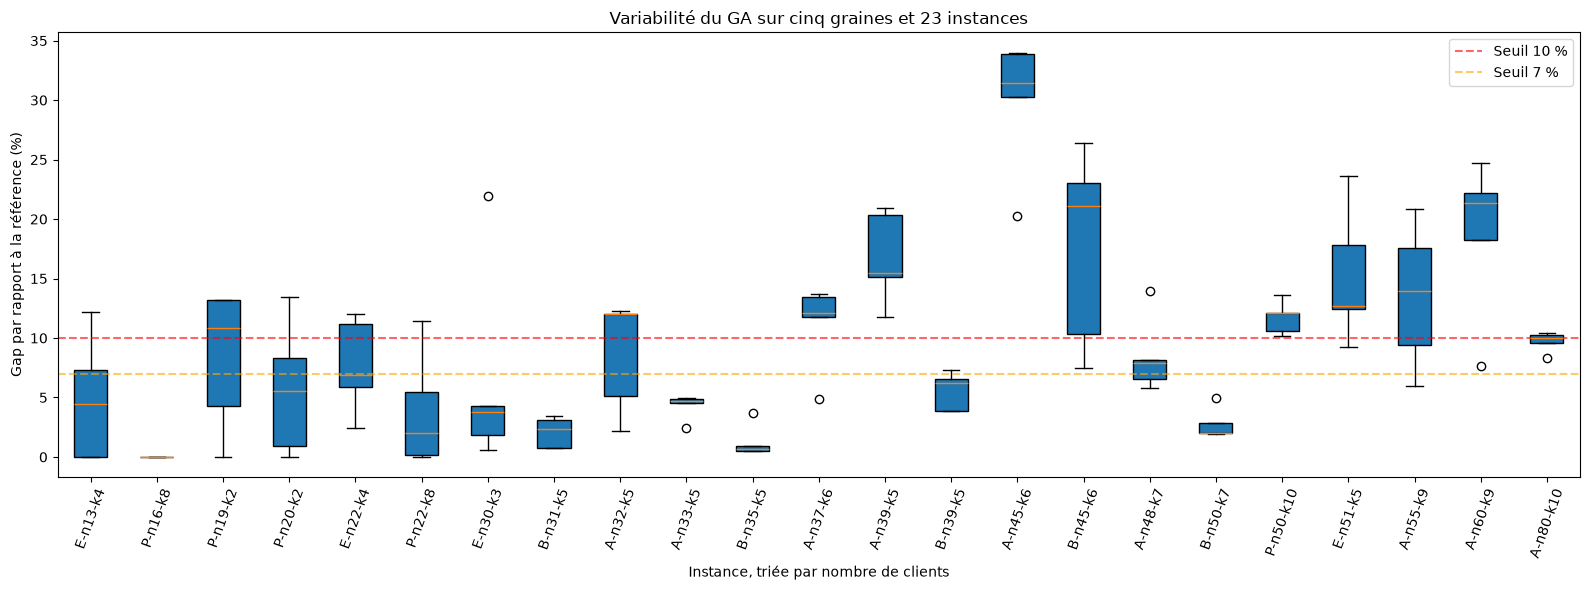

In [10]:
# Distribution des gaps sur les cinq graines, triée par taille d’instance
plot_data = df_multi.dropna(subset=['gap_num']).sort_values(['n_clients', 'instance'])
instance_names = plot_data['instance'].drop_duplicates().tolist()
box_data = [plot_data.loc[plot_data['instance'] == name, 'gap_num'].values
            for name in instance_names]
fig, ax = plt.subplots(figsize=(16, 6))
ax.boxplot(box_data, tick_labels=instance_names, patch_artist=True)
ax.set_ylabel('Gap par rapport à la référence (%)')
ax.set_xlabel('Instance, triée par nombre de clients')
ax.set_title('Variabilité du GA sur cinq graines et 23 instances')
ax.axhline(y=10, color='red', linestyle='--', alpha=0.6, label='Seuil 10 %')
ax.axhline(y=7, color='orange', linestyle='--', alpha=0.6, label='Seuil 7 %')
ax.legend()
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()


### Lecture du graphique de gaps

Les boîtes visualisent la variabilité entre les cinq graines. Une boîte étroite indique que la qualité varie peu selon l’initialisation ; une boîte large signale un résultat moins robuste. Les lignes à 7 % et 10 % repèrent les instances qui dépassent les seuils du cahier des charges. Le graphique complète les statistiques du tableau, mais ne remplace pas la comparaison aux références.

### 8.3 Comparaison PLNE vs GA à budget égal

Cette expérience compare directement les deux méthodes sur les instances de 30 clients ou moins, avec une limite maximale de cinq secondes chacune. Le GA utilise la graine 42. Le PLNE peut terminer avant cette limite s’il prouve l’optimalité ; sinon, son statut et sa borne inférieure sont rapportés.

In [11]:
# Comparaison directe à budget maximal identique sur les petites instances
from benchmark import compare_plne_vs_ga

df_compare = compare_plne_vs_ga(
    all_instances,
    max_clients=PLNE_GA_COMPARISON_MAX_CLIENTS,
    time_limit=PLNE_GA_COMPARISON_TIME_LIMIT,
    seed=EXPERIMENT_SEEDS[0],
)
df_compare


,instance,n_clients,time_limit_seconds_per_method,reference_cost,ga_cost,ga_gap_reference_percent,ga_elapsed_seconds,plne_status,plne_cost,plne_lower_bound,plne_gap_bound_percent,plne_elapsed_seconds
0,B-n31-k5,30,5.0,672.0,695.0,3.42,0.67,optimal,672.0,672.0,0.0,1.72
1,E-n13-k4,12,5.0,247.0,277.0,12.15,0.33,optimal,247.0,247.0,0.0,0.04
2,E-n22-k4,21,5.0,375.0,417.0,11.20,0.68,optimal,375.0,375.0,0.0,0.06
3,E-n30-k3,29,5.0,534.0,544.0,1.87,1.21,time_limit,inf,529.0,inf,5.00
4,P-n16-k8,15,5.0,450.0,450.0,0.00,0.38,optimal,450.0,450.0,0.0,0.39
5,P-n19-k2,18,5.0,212.0,235.0,10.85,0.42,optimal,212.0,212.0,0.0,0.39
6,P-n20-k2,19,5.0,216.0,218.0,0.93,0.43,optimal,216.0,216.0,0.0,0.37
7,P-n22-k8,21,5.0,603.0,603.0,0.00,0.61,time_limit,inf,596.0,inf,5.01


### Interprétation de la comparaison à budget égal

Sur huit instances avec une limite maximale de 5 secondes par méthode, le PLNE certifie l’optimum dans six cas. Il atteint la limite sans solution entière sur `E-n30-k3` et `P-n22-k8`, alors que le GA trouve des tournées de coût 544 et 603 (gaps de référence de 1,87 % et 0 %). Le temps maximal égal ne signifie pas que les durées réelles sont identiques : le GA s’arrête souvent par stagnation, et le PLNE peut s’arrêter dès qu’il prouve l’optimum. La comparaison illustre le rôle du PLNE comme référence quand il termine et celui du GA pour obtenir rapidement une solution faisable.

### 8.4 Passage à l'échelle sur des instances de référence (Scalabilité)

Pour répondre aux exigences de passage à l'échelle industrielle de l'ADEME, nous testons le GA sur des sous-instances progressives de la méga-instance belge `Leuven1` (contenant jusqu'à 3 000 clients dans `data/`), de 50 à 500 clients.


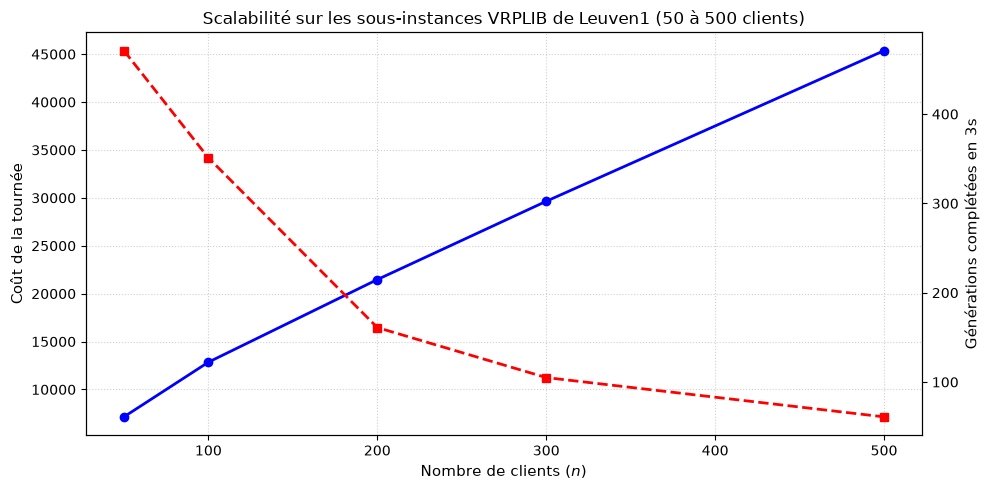

,n_clients,n_camions,coût_trouvé,faisable,temps (s),générations
0,50,50,7140.0,True,2.39,471
1,100,100,12848.0,True,3.00,351
2,200,200,21471.0,True,3.00,161
3,300,300,29642.0,True,3.00,105
4,500,500,45365.0,True,3.00,61


In [12]:
# Scalabilité sur des sous-instances de Leuven1 
from benchmark import run_scalability_benchmark

leuven_inst = load_instance(DATA / 'Leuven1.vrp')
df_scale = run_scalability_benchmark(
    leuven_inst, sizes=[50, 100, 200, 300, 500], max_time=3.0, seed=42
)
df_scale = df_scale.rename(columns={
    'n_vehicles': 'n_camions', 'cost': 'coût_trouvé',
    'feasible': 'faisable', 'elapsed_seconds': 'temps (s)',
    'generations': 'générations',
})
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlabel('Nombre de clients ($n$)', fontsize=11)
ax1.set_ylabel('Coût de la tournée', fontsize=11)
ax1.plot(df_scale['n_clients'], df_scale['coût_trouvé'], 'bo-', linewidth=2)
ax1.grid(True, linestyle=':', alpha=0.6)
ax2 = ax1.twinx()
ax2.set_ylabel('Générations complétées en 3s', fontsize=11)
ax2.plot(df_scale['n_clients'], df_scale['générations'], 'rs--', linewidth=2)
plt.title('Scalabilité sur les sous-instances VRPLIB de Leuven1 (50 à 500 clients)', fontsize=12)
fig.tight_layout()
plt.show()
df_scale


### Interprétation du passage à l’échelle

Sur les sous-instances Leuven1 de 50 à 500 clients, le GA trouve une solution faisable. À partir de 100 clients, il utilise le budget de 3 secondes ; les évaluations passent de 40 906 à 100 clients à 6 971 à 500 clients, car l’évaluation de chaque individu devient plus coûteuse. Les coûts augmentent avec la taille et ne sont pas comparables entre eux sans référence ou borne adaptée. Ces résultats démontrent la faisabilité et le temps borné dans ce test, pas la qualité optimale des solutions.

### 8.5 Analyse de sensibilité multi-graines & Robustesse stochastique

Nous étudions l'influence du **taux de mutation** ($p_{\text{mut}} \in [0.05, 0.50]$) en répétant chaque essai sur 5 graines différentes afin de tracer la courbe de sensibilité entourée de sa bande d'écart-type.


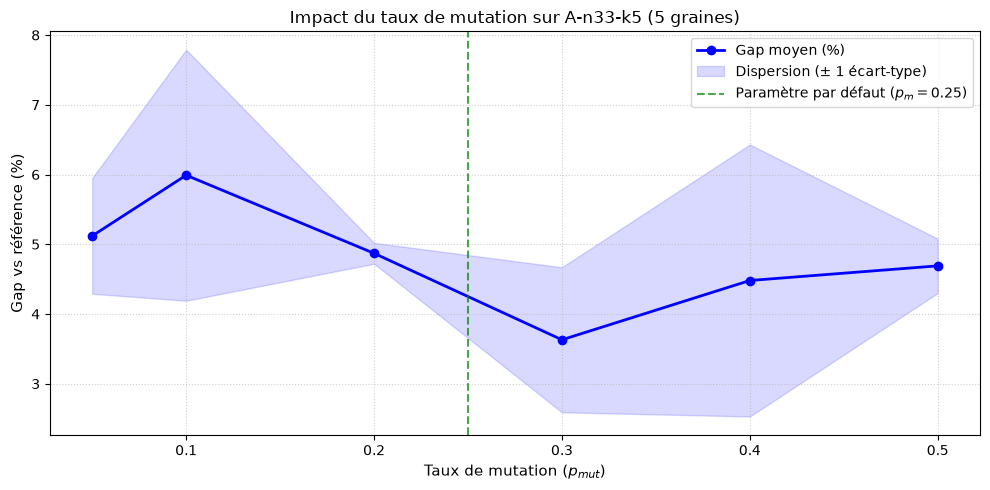

,mutation_rate,gap_mean_percent,gap_std_percent,gap_min_percent,gap_max_percent,time_mean_seconds
0,0.05,5.12,0.83,4.39,6.51,1.22
1,0.10,5.99,1.80,2.87,8.47,1.22
2,0.20,4.87,0.15,4.69,4.99,1.00
3,0.30,3.63,1.04,2.42,4.99,0.82
4,0.40,4.48,1.95,2.42,7.56,1.18
5,0.50,4.69,0.39,3.93,4.99,1.00


In [13]:
# Sensibilité au taux de mutation, avec cinq graines par paramètre
from benchmark import run_mutation_sensitivity

df_sens_multi = run_mutation_sensitivity(
    load_instance(DATA / 'A-n33-k5.vrp'),
    mutation_rates=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50],
    seeds=EXPERIMENT_SEEDS,
    max_time=2.0,
)
plt.figure(figsize=(10, 5))
x_vals = df_sens_multi['mutation_rate'].values
moyennes = df_sens_multi['gap_mean_percent'].values
deviations = df_sens_multi['gap_std_percent'].values
plt.plot(x_vals, moyennes, 'b-o', linewidth=2, label='Gap moyen (%)')
plt.fill_between(x_vals, moyennes - deviations, moyennes + deviations,
                 color='blue', alpha=0.15, label='Dispersion (± 1 écart-type)')
plt.axvline(x=0.25, color='green', linestyle='--', alpha=0.7, label='Paramètre par défaut ($p_m = 0.25$)')
plt.xlabel('Taux de mutation ($p_{mut}$)', fontsize=11)
plt.ylabel('Gap vs référence (%)', fontsize=11)
plt.title('Impact du taux de mutation sur A-n33-k5 (5 graines)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
df_sens_multi


### Interprétation de la sensibilité au taux de mutation

Sur `A-n33-k5`, le taux 0,30 donne le meilleur gap moyen (3,63 %) parmi les six valeurs testées. Le taux 0,20 est le plus stable (écart-type 0,15 point), avec un gap moyen de 4,87 %. Les taux 0,10 et 0,40 sont plus variables. Le taux 0,30 est donc le meilleur compromis observé sur cette instance, mais cinq graines et une seule instance ne suffisent pas à en faire un réglage universel.

### 8.6 Courbe de convergence du GA

Nous visualisons ici la trajectoire d'optimisation du meilleur individu au fil des générations pour analyser la dynamique de convergence et valider le critère d'arrêt par stagnation.


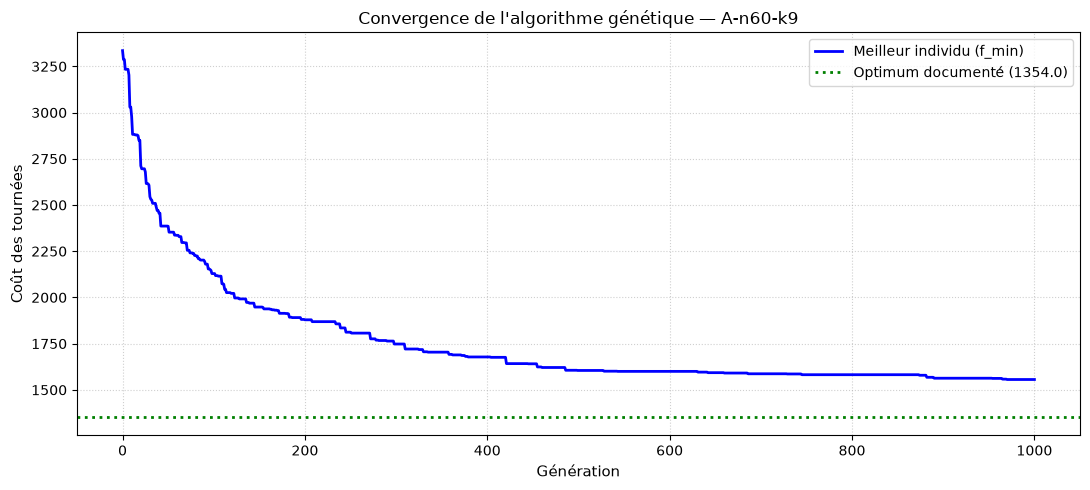

Coût final : 1556
Gap final : 14.92 %
Générations explorées : 1000
Temps de calcul : 6.07 s


In [16]:
# Courbe de convergence du GA sur A-n60-k9
ga.MAX_TIME_SECONDS = 15.0
ga.RANDOM_SEED = 42
ga.POPULATION_SIZE = 120
ga.MUTATION_PROBABILITY = 0.25
ga.MAX_GENERATIONS = 1000
ga.STAGNATION_GENERATIONS = 150

conv_inst = load_instance(DATA / 'A-n60-k9.vrp')
best_conv, stats_conv = ga.solve(conv_inst)

# Extraction de la trajectoire
history = stats_conv['history']
gens = [h['generation'] for h in history]
costs = [h['best_cost'] for h in history]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(gens, costs, 'b-', linewidth=2.0, label='Meilleur individu (f_min)')

if conv_inst.best_known:
    ax.axhline(y=conv_inst.best_known, color='green', linestyle=':', linewidth=2,
              label=f'Optimum documenté ({conv_inst.best_known})')

ax.set_xlabel('Génération', fontsize=11)
ax.set_ylabel('Coût des tournées', fontsize=11)
ax.set_title(f'Convergence de l\'algorithme génétique — {conv_inst.name}', fontsize=12)
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print(f'Coût final : {best_conv.cost:g}')
print(f'Gap final : {gap(best_conv.cost, conv_inst.best_known):.2f} %')
print(f'Générations explorées : {stats_conv["completed_generations"]}')
print(f'Temps de calcul : {stats_conv["search_seconds"]:.2f} s')


### Interprétation de la convergence

Sur `A-n60-k9`, le GA termine les 1 000 générations en 5,68 secondes et obtient un coût de 1 556, soit un gap de référence de 14,92 %. L’algorithme a donc continué à explorer jusqu’à sa limite de générations sans atteindre une solution proche de la référence. Cette courbe décrit une exécution particulière et ne constitue pas une preuve de convergence vers l’optimum.

### 8.7 Visualisation cartographique des tournées

Nous représentons graphiquement dans le plan 2D les tournées optimisées obtenues par le GA sur deux instances avec coordonnées clients et dépôt.


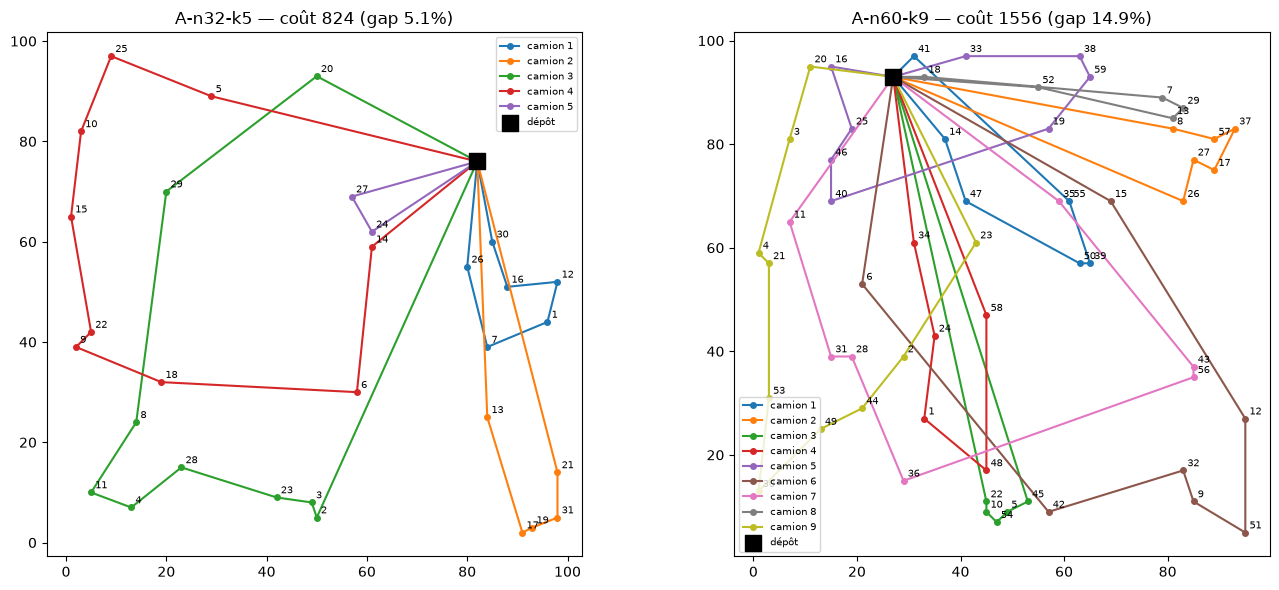

In [15]:
# Visualisation sur 2 instances VRPLIB ayant des coordonnées
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

viz_instances = [load_instance(DATA / 'A-n32-k5.vrp'), load_instance(DATA / 'A-n60-k9.vrp')]
for i, vinst in enumerate(viz_instances):
    ga.MAX_TIME_SECONDS = 20.0
    ga.RANDOM_SEED = 42
    ga.POPULATION_SIZE = 120
    ga.MUTATION_PROBABILITY = 0.25
    best_viz, _ = ga.solve(vinst)
    if best_viz and vinst.coords is not None:
        g = gap(best_viz.cost, vinst.best_known) if vinst.best_known else 0
        plot_solution(vinst, best_viz.routes, ax=axes[i],
                      title=f'{vinst.name} — coût {best_viz.cost:g} (gap {g:.1f}%)')

plt.tight_layout()
plt.show()

### Interprétation des cartes de tournées

Les cartes de `A-n32-k5` et `A-n60-k9` rendent visibles l’organisation géographique des tournées et le retour au dépôt. Elles servent de contrôle qualitatif et facilitent la lecture des solutions ; la faisabilité et la qualité restent établies par les contraintes vérifiées, le coût et le gap, pas par l’apparence seule.

### 8.8 Synthèse de l’étude expérimentale

Les expériences montrent le compromis attendu : le GA produit rapidement des tournées faisables sur les 23 instances et passe à 500 clients dans le test Leuven1, mais son gap dépasse 10 % sur plusieurs cas et sa stabilité varie selon l’instance. Le PLNE certifie plusieurs optima sur les petites instances, mais certaines atteignent leur limite de temps même sous 30 clients ; le seuil dépend donc des données et du budget, pas seulement de la taille.

La comparaison à budget égal confirme la complémentarité des méthodes : le PLNE donne une preuve d’optimalité quand il termine, tandis que le GA peut fournir un incumbent faisable quand le PLNE ne termine pas. Les références VRPLIB restent des solutions connues, sauf certification explicite. Les résultats et leurs limites sont détaillés immédiatement après chaque tableau ou graphique ci-dessus.

## 9. Conclusion, limites et Plan d'Amélioration Stratégique

### Bilan du projet
Ce projet combine une modélisation du CVRP, une résolution exacte pour produire des références sur certaines petites instances, et un algorithme génétique pour rechercher rapidement des tournées réalisables. Les expériences conduisent aux constats suivants :
- **PLNE** : le Branch and Bound certifie l’optimalité sur 6 des 8 petites instances de la comparaison à 5 secondes. Il atteint la limite sur deux autres ; la réussite dépend donc de l’instance et du budget, sans seuil fixe en nombre de clients.
- **GA** : les solutions sont faisables sur les 23 instances. Sur cinq graines, le gap moyen des moyennes par instance est d’environ 9,33 % ; 8 instances ont un gap moyen supérieur à 10 %. Certaines références sont atteintes, mais la qualité reste insuffisante sur les cas difficiles.
- **Passage à l’échelle** : sur les sous-instances Leuven1 de 50 à 500 clients, le GA fournit une solution faisable dans le budget testé de 3 secondes. Ces essais ne disposent pas d’une référence optimale pour mesurer le gap.

---

### Limites identifiées
1. **Qualité du GA** : le gap dépasse 10 % sur plusieurs instances, notamment dans la série A et sur `B-n45-k6`. Le Split glouton ne cherche pas le découpage de coût minimal.
2. **Variabilité** : les cinq graines donnent des dispersions très différentes selon les instances ; une seule exécution ne suffit pas à juger la méthode.
4. **Références** : les fichiers `.sol` représentent des solutions de référence, pas nécessairement des optima certifiés. Les gaps présentés sont des gaps par rapport à ces références, sauf lorsque le PLNE prouve explicitement l’optimum.
5. **Modèle simplifié** : les fenêtres de livraison et le trafic dépendant de l’heure ne sont pas pris en compte.

### Axes d’amélioration
1. Remplacer le Split glouton par un Split optimisé par programmation dynamique.
2. Ajouter une recherche locale (2-opt*, or-opt, relocate, exchange) après le décodage des tournées.
3. Étudier une méthode ALNS et l’hybridation avec le GA.
4. Étendre le modèle au CVRPTW et au trafic dépendant de l’heure si les données sont disponibles.

Les résultats soutiennent le choix du GA comme méthode retenue pour les grandes instances, tout en gardant le PLNE comme référence lorsque celui-ci peut certifier l’optimalité.

## 10. Références bibliographiques

- Dantzig, G.B. & Ramser, J.H. (1959). *The Truck Dispatching Problem*. Management Science, 6(1), 80-91. — Formulation originale du VRP.
- Clarke, G. & Wright, J.W. (1964). *Scheduling of vehicles from a central depot to a number of delivery points*. Operations Research, 12(4), 568-581. — Heuristique des économies.
- [P versus NP : exemple dans un réseau social](https://www.youtube.com/watch?v=rkDlTQFucBM), Rachid Guerraoui — Complexité et distinction P/NP.
- [Programmation linéaire](https://www.techniques-ingenieur.fr/ressources-documentaires/sciences-fondamentales-th8/mathematiques-ti052/programmation-lineaire-af1254), Techniques de l'ingénieur.
- [Programmation linéaire et PuLP](https://scenari.cesi.fr/scenari/cas/Diffusion_FISE_INFO_A3_Algorithmique_et_optimisation_26_27_ETU/res/PRogLineMaire_Et_Pulp_V1.pdf), support pédagogique CESI.
- [La modélisation — Recherche opérationnelle](https://www.youtube.com/watch?v=Zy-iTwA9tfU), démarche de modélisation.